In [1]:
## simulate mock community (and niche specific communities) for
# shorter amplicons with ART and with random mutations for full-length amplicons
## Steps involves 1) simulation of abundance 2) generate fasta and taxonomies based on simulated abundance
# 3) simulate reads with ART for shorter amplicons and random mutations for full-length amplicons
# 4) feature table generation with dada2 for shorter amplicons, while no such processing needed for full-length
# 5) guess trueish taxonomies by gapless alignment for simulated sequences for shorter amplicon, while for full-length amplicons use species level taoxnomies as it is
# 6) outcome is we have for each mock community and v-region we have rep_seq.fasta file for classification and trueish taxonomy txt file as a ground truth

import os
import subprocess
import random
import shutil
import hashlib
from os.path import join, exists, expandvars, dirname
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
from biom import Table
import src.utils
import src.extract_reads
import src.process_mock
%matplotlib inline

In [2]:
## set path vars
n_cpus = os.cpu_count() - 1
n_jobs = 1 # number_of_jobs to run in parallel
analysis_name = "mock-community"
project_dir = expandvars("/home/kardokhk/taxonova_bench")
conda_dir = join(project_dir, "conda")
scripts_dir = join(project_dir, f"scripts/mock-community/src")
reference_database_dir = join(project_dir, f"benchmark/data/ref_dbs")
mock_dir = join(project_dir, f"benchmark/data", analysis_name)

## set params
nsamples = 10 # number of samples to simulate abundance
nfeatures = None # number of sequence-ids for random sampling [None means auto selects ~80% of the features]
nsamples_rep = 3 # number of replicates of samples to generate with ART for each simulated sample abundance
nreads_per_feature = 5 # number of read or read-pairs to generate per feature
min_mutation = 0.002 # lower mutation range for full-length amplicon simulations (corrosponds to ~3 SNPs for 1500bp)
max_mutation = 0.02  # upper mutation range for full-length amplicon simulations (corrosponds to ~30 SNPs for 1500bp)

In [3]:
## Pipeline params
# name of the mock communities
mock_names = ['gutmock', 'vaginalmock', 'mockrobiota-16S', 'mockrobiota-ITS']

# amplicon regions
v_regions = ['V4', 'V3-V4', 'ITS1', 'ITS2', 'V1-V9', 'ITS12']

# amplicon regions (mostly full-length) that won't be simulated with ART
full_length_regions = ['V1-V9', 'ITS12']

# mock to v_region mapping
mock_v_regions = {
    'gutmock': ['V4', 'V3-V4', 'V1-V9'],
    'vaginalmock': ['V4', 'V3-V4', 'V1-V9'],
    'mockrobiota-16S': ['V4', 'V3-V4', 'V1-V9'],
    'mockrobiota-ITS': ['ITS1', 'ITS2', 'ITS12']
}

# paired-end read
paired = {
    'V4': True,
    'V3-V4': True,
    'ITS1': True,
    'ITS2': True
}

# length of read
length_reads = {
    'V4': 250,
    'V3-V4': 250,
    'ITS1': 250,
    'ITS2': 250,
}

# sequencing system
sequencing_system = {
    'V4': 'MSv3',
    'V3-V4': 'MSv3',
    'ITS1': 'MSv3',
    'ITS2': 'MSv3'
}

# mean size of DNA fragments for ART
mlength_reads = {
    'V4': 300,
    'V3-V4': 450,
    'ITS1': 350,
    'ITS2': 400
}


In [4]:
## read-in seqs and taxa file for each mock communities
# Mock community input dir
mock_files_dir = join(mock_dir, "input_data")

# Add to seqs and taxa to database
mock_files = {}
for mock_name in mock_names:
    mock_files[mock_name] = {}
    # check dir and copy files to respective dirs
    mockdir = join(mock_dir, mock_name, 'src')
    mock_seqs = join(mockdir, f'{mock_name}_seqs.fasta')
    mock_taxa = join(mockdir, f'{mock_name}_taxa.txt')

    src.utils.check_dir(mockdir)
    if not Path(mock_seqs).exists() and not Path(mock_taxa).exists():
        # copy to dir
        shutil.copy(join(mock_files_dir, f'{mock_name}_seqs.fasta'), mockdir)
        shutil.copy(join(mock_files_dir, f'{mock_name}_taxa.txt'), mockdir)
        
        # update to dict
        mock_files[mock_name]['seq'] = join(mockdir, f'{mock_name}_seqs.fasta')
        mock_files[mock_name]['taxa'] = join(mockdir, f'{mock_name}_taxa.txt')
    else:
        mock_files[mock_name]['seq'] = join(mockdir, f'{mock_name}_seqs.fasta')
        mock_files[mock_name]['taxa'] = join(mockdir, f'{mock_name}_taxa.txt') 

mock_files

{'gutmock': {'seq': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/src/gutmock_seqs.fasta',
  'taxa': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/src/gutmock_taxa.txt'},
 'vaginalmock': {'seq': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/vaginalmock/src/vaginalmock_seqs.fasta',
  'taxa': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/vaginalmock/src/vaginalmock_taxa.txt'},
 'mockrobiota-16S': {'seq': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-16S/src/mockrobiota-16S_seqs.fasta',
  'taxa': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-16S/src/mockrobiota-16S_taxa.txt'},
 'mockrobiota-ITS': {'seq': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-ITS/src/mockrobiota-ITS_seqs.fasta',
  'taxa': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-ITS/src/mockrobiota-ITS_taxa.txt'}}

In [5]:
## For each mock_name, load mock community files and simulate abundance
random.seed(123)
np.random.seed(123)
for mock_name in mock_files.keys():
    # Load mock community file
    db_dict = src.utils.load_db_from_files(taxa_path = mock_files[mock_name]['taxa'])

    # add prefixes, join taxa into string and prepare list
    all_taxonomies = [
        src.utils.join_taxa_lineages(record['taxa']) for ID, record in db_dict.items()
    ]

    # List of all available sequence IDs
    mockro_ids = list(db_dict.keys())

    # taxon lookup from ID to Taxon
    id_to_taxon = {ID: src.utils.join_taxa_lineages(record['taxa']) for ID, record in db_dict.items()}

    # sample generation loop
    abun_tab = None
    feature_tab = None
    for i in range(nsamples):
        sample_name = f"{mock_name}0{i}"

        # randomly select 80% of ids with some variability
        k = int(len(mockro_ids) * 0.8 + random.randint(-2, 2))
        k = max(1, min(len(mockro_ids), k)) 
        chosen_ids = random.sample(mockro_ids, k=k)

        # get associated taxa
        all_taxonomies = [id_to_taxon[ID] for ID in chosen_ids]
        unique_taxa = list(set(all_taxonomies))

        # generate random abundances at taxon level
        rand_vals = np.random.rand(len(unique_taxa))
        rand_relab = rand_vals / rand_vals.sum()
        taxon_abundance = dict(zip(unique_taxa, rand_relab))

        # taxon abundance table
        this_abun = pd.DataFrame({'Taxon': unique_taxa})
        this_abun[sample_name] = this_abun['Taxon'].map(taxon_abundance)
        this_abun = this_abun.set_index('Taxon')

        # map Taxon to sequence IDs
        taxon_to_ids = defaultdict(list)
        for ID in chosen_ids:
            taxon = id_to_taxon[ID]
            taxon_to_ids[taxon].append(ID)

        # generate feature table by distributing taxon abundance across sequence IDs
        id_abundances = defaultdict(float)
        for taxon, abun in taxon_abundance.items():
            ids = taxon_to_ids[taxon]
            rand_vals = np.random.rand(len(ids))
            rand_props = rand_vals / rand_vals.sum()
            for sid, prop in zip(ids, rand_props):
                id_abundances[sid] += abun * prop

        # dataFrame
        this_feat = pd.Series(id_abundances).to_frame(name=sample_name)

        # merge tables
        if i == 0:
            abun_tab = this_abun
            feature_tab = this_feat
        else:
            abun_tab = abun_tab.join(this_abun, how='outer').fillna(0)
            feature_tab = feature_tab.join(this_feat, how='outer').fillna(0)

    # finalize
    abun_tab = abun_tab.reset_index()
    abun_tab.iloc[:, 1:] = abun_tab.iloc[:, 1:].round(6)
    feature_tab = feature_tab.reset_index().rename(columns={'index': 'ID'})
    feature_tab.iloc[:, 1:] = feature_tab.iloc[:, 1:].round(6)

    mockdir = join(mock_dir, mock_name, 'src')
    # save abundance table
    exp_tax_mockro = join(mockdir, "expected-taxonomy.tsv")
    if not exists(exp_tax_mockro):
        abun_tab.to_csv(exp_tax_mockro, sep="\t", index=False)

    # save feature table
    feature_tab_mockro = join(mockdir, "expected-featuretab.tsv")
    if not exists(feature_tab_mockro):
        feature_tab.to_csv(feature_tab_mockro, sep="\t", index=False)

In [6]:
## check dirs and prepare dicts
db_out_files = {}
abundance_tabs, feature_tab = {}, {}
for v_region in v_regions:
    # initialise once per v_region
    db_out_files[v_region] = {}
    abundance_tabs[v_region], feature_tab[v_region] = {}, {}
    for mock_name in mock_names:
        # skip if region to mock mismatch
        if v_region not in mock_v_regions[mock_name]:
            continue
        
        mockdir = join(mock_dir, mock_name, 'src')
        # Output directory
        db_out_files[v_region][mock_name] = join(mock_dir, mock_name, v_region)
        src.utils.check_dir(db_out_files[v_region][mock_name])

        # Read the abundance_tables
        abundance_tabs[v_region][mock_name] = pd.read_csv(
            join(mockdir, 'expected-taxonomy.tsv'), sep = "\t", 
            header = 0, index_col = None)
        
        # Read the feature tables
        feature_tab[v_region][mock_name] = pd.read_csv(
            join(mockdir, "expected-featuretab.tsv"), sep = "\t", 
            header = 0, index_col = 'ID')
        
db_out_files

{'V4': {'gutmock': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V4',
  'vaginalmock': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/vaginalmock/V4',
  'mockrobiota-16S': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-16S/V4'},
 'V3-V4': {'gutmock': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V3-V4',
  'vaginalmock': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/vaginalmock/V3-V4',
  'mockrobiota-16S': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-16S/V3-V4'},
 'ITS1': {'mockrobiota-ITS': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-ITS/ITS1'},
 'ITS2': {'mockrobiota-ITS': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-ITS/ITS2'},
 'V1-V9': {'gutmock': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V1-V9',
  'vaginalmock': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community

In [7]:
## Extract amplicon region based on primer-set
v_primers = src.utils.get_vregion_primers()
v_length = src.utils.get_vregion_lengths()

# cut reads and keep only entries with both sequence and taxonomy information
db_unqza = {}
out_seqs_file = {}
db_mockro = {}
for v_region in v_regions:
    db_unqza[v_region] = {}
    out_seqs_file[v_region] = {}
    db_mockro[v_region] = {}
    for mock_name in mock_names:
        # skip if region to mock mismatch
        if v_region not in mock_v_regions[mock_name]:
            continue
        
        out_seqs_file[v_region][mock_name] = {}
        # check dir
        mockdir = join(mock_dir, mock_name, 'src',  'extracted_regions')
        src.utils.check_dir(mockdir)

        # out_files
        checkpoint = Path(join(mockdir, f'{mock_name}_{v_region}_done'))
        taxa_out = join(mockdir, f'{mock_name}_{v_region}_taxa.txt')
        seqs_out = join(mockdir, f'{mock_name}_{v_region}_seqs.fasta')
        
        if not checkpoint.exists():
            # cut reads
            src.extract_reads.cutter(
                sequences = mock_files[mock_name]['seq'], 
                f_primer = v_primers[v_region]['f'],
                r_primer = v_primers[v_region]['r'], 
                min_length = v_length[v_region]['min'], 
                max_length = v_length[v_region]['max'],
                n_jobs = n_cpus,
                output_path = seqs_out)
            out_seqs_file[v_region][mock_name]['fasta'] = seqs_out

            # filter and update seq and taxa file
            db_mockro[v_region][mock_name] = src.utils.load_db_from_files(
                taxa_path = mock_files[mock_name]['taxa'], 
                seqs_path = out_seqs_file[v_region][mock_name]['fasta']
            )
            src.utils.download_db_from_dict(
                db_mockro[v_region][mock_name],
                taxa_out_file = taxa_out,
                seqs_out_file = seqs_out 
            )

            # update to dict
            db_unqza[v_region][mock_name] = {
                'seq': seqs_out, 'taxa': taxa_out 
            }

            # mark complete
            checkpoint.touch()
        else:
            # update to dict
            db_unqza[v_region][mock_name] = {
                'seq': seqs_out, 'taxa': taxa_out 
            }

db_unqza    

/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn(
/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn(
/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn

3 entries without sequence or taxa information were deleted


/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn(
/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn(
/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn

2 entries without sequence or taxa information were deleted


/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn(
/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn(
/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn

11 entries without sequence or taxa information were deleted
1 entries without sequence or taxa information were deleted


... (5 outputs left out)

15 entries without sequence or taxa information were deleted


/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn(
/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn(
/home/kardokhk/miniforge3/envs/mock-taxonomy/lib/python3.10/site-packages/skbio/util/_warning.py:56: DeprecationWarning: local_pairwise_align_ssw is deprecated as of 0.5.8. It will be removed in favor of more general purpose and performant aligners. Additional details at https://github.com/scikit-bio/scikit-bio/issues/1814.
  warn

116 entries without sequence or taxa information were deleted
23 entries without sequence or taxa information were deleted
76 entries without sequence or taxa information were deleted
24 entries without sequence or taxa information were deleted


{'V4': {'gutmock': {'seq': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/src/extracted_regions/gutmock_V4_seqs.fasta',
   'taxa': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/src/extracted_regions/gutmock_V4_taxa.txt'},
  'vaginalmock': {'seq': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/vaginalmock/src/extracted_regions/vaginalmock_V4_seqs.fasta',
   'taxa': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/vaginalmock/src/extracted_regions/vaginalmock_V4_taxa.txt'},
  'mockrobiota-16S': {'seq': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-16S/src/extracted_regions/mockrobiota-16S_V4_seqs.fasta',
   'taxa': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-16S/src/extracted_regions/mockrobiota-16S_V4_taxa.txt'}},
 'V3-V4': {'gutmock': {'seq': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/src/extracted_regions/gutmock_V3-V4_seqs.fasta',
  

In [8]:
## Create fasta sequences and identifiers by simulating the environment
env_fastas, env_abun_dfs = {}, {}
for v_region in v_regions:
    env_fastas[v_region] = {}
    env_abun_dfs[v_region] = {}
    for mock_name in mock_names:
        # skip if region to mock mismatch
        if v_region not in mock_v_regions[mock_name]:
            continue
        
        # dicts and out_file
        env_fastas[v_region][mock_name] = {}
        tab = feature_tab[v_region][mock_name]
        outdir = db_out_files[v_region][mock_name]
        out_abun_tab = join(outdir, 'env_abundance.tsv')

        if not Path(out_abun_tab).exists():
            # download env fasta and taxa with filtering only those included in the samples
            env = src.utils.load_db_from_files(seqs_path = db_unqza[v_region][mock_name]['seq'],
                                               taxa_path = db_unqza[v_region][mock_name]['taxa'])
            env = {ID: item for ID, item in env.items() if ID in tab.index}
            
            # initialize abundance table
            env_abun_tab = pd.DataFrame(index=abundance_tabs[v_region][mock_name]['Taxon'])

            for sample in tab.columns:
                # output files
                sample_fasta = join(outdir, f"env-seqs_{sample}.fasta")
                sample_identifiers = join(outdir, f"env-identifiers_{sample}.tsv")

                # list chosen ids with non-zero abundance
                ids = list(tab[tab[sample]>0].index)
                sample_env = {ID: item for ID, item in env.items() if ID in ids}

                # download sample fasta
                src.utils.download_db_from_dict(sample_env, seqs_out_file = sample_fasta)
                env_fastas[v_region][mock_name][sample] = sample_fasta
                samp_taxonomies = [src.utils.join_taxa_lineages(record['taxa']) 
                                   for ID, record in sample_env.items()]
                
                # create env-identifiers
                env_identifiers = {}
                for i in sample_env.keys():
                    tax = src.utils.join_taxa_lineages(sample_env[i]['taxa'])
                    env_identifiers.setdefault(tax, []).append(i)

                # write env-identifiers file
                with open(sample_identifiers, 'w') as fh:
                    fh.write(f"Taxa\tAbundance\tIDs\n")
                    for tax, ids in env_identifiers.items():
                        id_line = ','.join(ids)
                        n = len(ids)
                        fh.write(f"{tax}\t{n}\t{id_line}\n")

                # update env_abundance table
                abun = pd.Series(samp_taxonomies).value_counts().to_frame(
                ).rename(columns={"count": sample})
                env_abun_tab = env_abun_tab.join(abun, how='outer').fillna(0)

            # download abun_tab
            env_abun_tab = env_abun_tab.reset_index().rename(columns = {'index': 'Taxon'})
            env_abun_tab.to_csv(out_abun_tab, sep="\t", index=False)
            env_abun_dfs[v_region][mock_name] = out_abun_tab
        else:
            # env abundance file
            env_abun_dfs[v_region][mock_name] = out_abun_tab
            
            # sample files
            for sample in tab.columns:
                sample_fasta = join(outdir, f"env-seqs_{sample}.fasta")
                env_fastas[v_region][mock_name][sample] = sample_fasta

env_fastas


{'V4': {'gutmock': {'gutmock00': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V4/env-seqs_gutmock00.fasta',
   'gutmock01': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V4/env-seqs_gutmock01.fasta',
   'gutmock02': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V4/env-seqs_gutmock02.fasta',
   'gutmock03': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V4/env-seqs_gutmock03.fasta',
   'gutmock04': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V4/env-seqs_gutmock04.fasta',
   'gutmock05': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V4/env-seqs_gutmock05.fasta',
   'gutmock06': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V4/env-seqs_gutmock06.fasta',
   'gutmock07': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V4/env-seqs_gutmock07.fasta',
   'gutmock08': '/home/kardokhk/taxonova_bench/benchmark/data/m

In [9]:
## Next, simulate reads using art_illumina [excluding full-length amplicon region]
fq_out_dirs = {}
for v_region in v_regions:
    # skip full-length regions
    if v_region in full_length_regions:
        continue

    fq_out_dirs[v_region] = {}
    for mock_name, val in env_fastas[v_region].items():
        for sample, path_fasta in val.items():
            
            dir_out = dirname(path_fasta)
            # Run simulation
            art_out = src.process_mock.art_simulation(
                input_fasta = path_fasta, output_prefix = sample,
                dir_out = join(dir_out, "source"), 
                seq_method = sequencing_system[v_region], 
                length = length_reads[v_region],
                mlen = mlength_reads[v_region],
                paired = paired[v_region], 
                count = nreads_per_feature, n_samples = nsamples_rep, 
                seed=1, force=True, parallel_jobs=n_cpus)
        # update dict with path from first sample
        fq_out_dirs[v_region][mock_name] = os.path.dirname(art_out[0])

fq_out_dirs

{'V4': {'gutmock': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V4/source/paired',
  'vaginalmock': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/vaginalmock/V4/source/paired',
  'mockrobiota-16S': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-16S/V4/source/paired'},
 'V3-V4': {'gutmock': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V3-V4/source/paired',
  'vaginalmock': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/vaginalmock/V3-V4/source/paired',
  'mockrobiota-16S': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-16S/V3-V4/source/paired'},
 'ITS1': {'mockrobiota-ITS': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-ITS/ITS1/source/paired'},
 'ITS2': {'mockrobiota-ITS': '/home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-ITS/ITS2/source/paired'}}

In [10]:
## Qiime2 processing [excluding full-length amplicon region]
# importing and demultiplexing
demultiplex = {}
for v_region in v_regions:
    # skip full-length regions
    if v_region in full_length_regions:
        continue

    demultiplex[v_region] = {}
    for mock_name, fq_out_dir in fq_out_dirs[v_region].items():
        out_dir = db_out_files[v_region][mock_name]
        demux, demux_viz, qiime_out = src.process_mock.qiime_demultiplex(
            out_dir = join(out_dir, "source"), 
            fq_out_dir=fq_out_dir, 
            paired=paired[v_region],
            force=True)
        demultiplex[v_region][mock_name] = [demux, demux_viz, qiime_out]

# dada2 processing
dada2 = {}
for v_region in v_regions:
    # skip full-length regions
    if v_region in full_length_regions:
        continue

    dada2[v_region] = {}
    for mock_name, items in demultiplex[v_region].items():
        qiime_out = items[2]
        demux = items[0]
        print(f"\n### {mock_name} - {v_region} \n")
        table, rep_seqs_sim, stats = src.process_mock.denoise_dada2(
            qiime_out, mock_name, demux, threads = n_cpus, 
            force = True, paired=paired[v_region])
        dada2[v_region][mock_name] = [table, rep_seqs_sim, stats]


### gutmock - V4 

Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: run_dada.R --input_directory /tmp/tmpiofdm9mm/forward --input_directory_reverse /tmp/tmpiofdm9mm/reverse --output_path /tmp/tmpiofdm9mm/output.tsv.biom --output_track /tmp/tmpiofdm9mm/track.tsv --filtered_directory /tmp/tmpiofdm9mm/filt_f --filtered_directory_reverse /tmp/tmpiofdm9mm/filt_r --truncation_length 0 --truncation_length_reverse 0 --trim_left 0 --trim_left_reverse 0 --max_expected_errors 2.0 --max_expected_errors_reverse 2.0 --truncation_quality_score 2 --min_overlap 12 --pooling_method independent --chimera_method consensus --min_parental_fold 1.0 --allow_one_off False --num_threads 71 --learn_min_reads 1000000

R version 4.3.3 (2024-02-29) 


Loading required package: Rcpp


DADA2: 1.30.0 / Rcpp: 1.0.14 / RcppParallel: 5.1.9 
2) Filtering ..............................
3) Learning Error Rates
9922500 total bases in 39690 reads from 30 samples will be used for learning the error rates.
9922500 total bases in 39690 reads from 30 samples will be used for learning the error rates.
3) Denoise samples ..............................
..............................
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output

### vaginalmock - V4 

Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: run_dada.R --input_directory /tmp/tmptw3mcw2x/forward --input_directory_reverse /tmp/tmptw3mcw2x/reverse --output_path /tmp/tmptw3mcw2x/output.tsv.biom --output_track /tmp/tmptw3mcw2x/track.tsv --filtered_directory /tmp/tmptw3mcw2x/filt_f --fil

Loading required package: Rcpp


DADA2: 1.30.0 / Rcpp: 1.0.14 / RcppParallel: 5.1.9 
2) Filtering ..............................
3) Learning Error Rates
2073750 total bases in 8295 reads from 30 samples will be used for learning the error rates.
2073750 total bases in 8295 reads from 30 samples will be used for learning the error rates.
3) Denoise samples ..............................
..............................
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output

### mockrobiota-16S - V4 

Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: run_dada.R --input_directory /tmp/tmp_2hm3r08/forward --input_directory_reverse /tmp/tmp_2hm3r08/reverse --output_path /tmp/tmp_2hm3r08/output.tsv.biom --output_track /tmp/tmp_2hm3r08/track.tsv --filtered_directory /tmp/tmp_2hm3r08/filt_f --f

Loading required package: Rcpp


... (8 outputs left out)

DADA2: 1.30.0 / Rcpp: 1.0.14 / RcppParallel: 5.1.9 
2) Filtering ..............................
3) Learning Error Rates
247500 total bases in 990 reads from 30 samples will be used for learning the error rates.
247500 total bases in 990 reads from 30 samples will be used for learning the error rates.
3) Denoise samples ..............................
..............................
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output

### mockrobiota-ITS - ITS2 

Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: run_dada.R --input_directory /tmp/tmp6ysp9ykv/forward --input_directory_reverse /tmp/tmp6ysp9ykv/reverse --output_path /tmp/tmp6ysp9ykv/output.tsv.biom --output_track /tmp/tmp6ysp9ykv/track.tsv --filtered_directory /tmp/tmp6ysp9ykv/filt_f --fil

Loading required package: Rcpp


DADA2: 1.30.0 / Rcpp: 1.0.14 / RcppParallel: 5.1.9 
2) Filtering ..............................
3) Learning Error Rates
742500 total bases in 2970 reads from 30 samples will be used for learning the error rates.
742500 total bases in 2970 reads from 30 samples will be used for learning the error rates.
3) Denoise samples ..............................
..............................
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output


<Figure size 640x480 with 0 Axes>


### V4 ## gutmock ###

d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__Prevotella; s__Hallella seregens and
d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__Prevotella; s__Prevotella dentalis
with 0 mismatches
d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__Prevotella; s__Prevotella ruminicola and
d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__Prevotella; s__Xylanibacter ruminicola
with 0 mismatches
d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__Prevotella; s__Hallella multisaccharivorax and
d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__Prevotella; s__Prevotella multisaccharivorax
with 0 mismatches
d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__Prevotella; s__Prevotella nanceiensis and
d__Bacteria; p__Bacteroidota; c__B

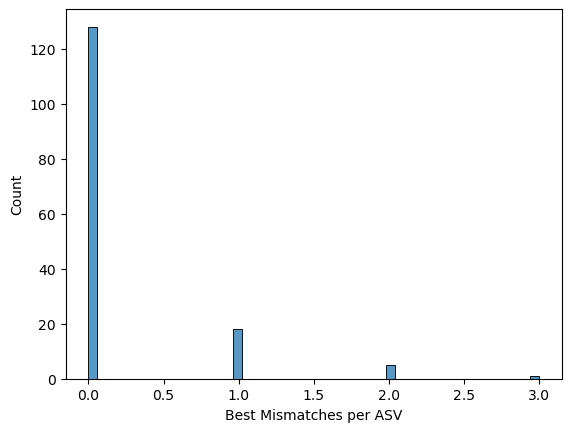

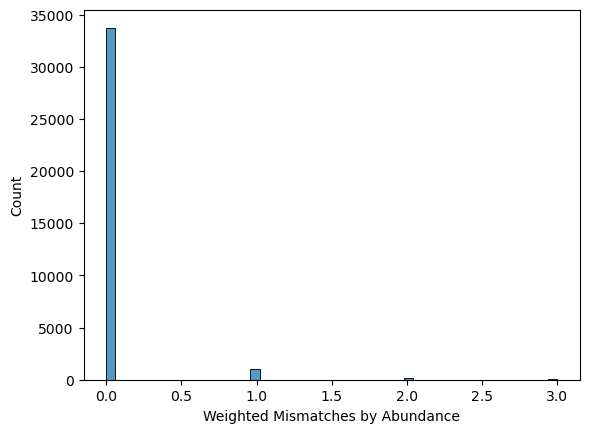


### V3-V4 ## vaginalmock ###

d__Bacteria; p__Bacillota_I; c__Bacilli_A; o__Lactobacillales; f__Lactobacillaceae; g__Lactobacillus; s__Lactobacillus paragasseri and
d__Bacteria; p__Bacillota_I; c__Bacilli_A; o__Lactobacillales; f__Lactobacillaceae; g__Lactobacillus; s__Lactobacillus gasseri
with 0 mismatches
Guessed taxonomy for 8150 of 8150 reads (100.0%)

### V3-V4 ## mockrobiota-16S ###

d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__Bacteroides_H_857956; s__Bacteroides_H_857956 xylanisolvens and
d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__Bacteroides_H_857956; s__Bacteroides_H_857956 ovatus
with 0 mismatches
d__Bacteria; p__Actinomycetota; c__Actinomycetes; o__Mycobacteriales; f__Micromonosporaceae; g__Micromonospora_H_372070; s__Salinispora arenicola and
d__Bacteria; p__Actinomycetota; c__Actinomycetes; o__Mycobacteriales; f__Micromonosporaceae; g__Micromonospora_H_372070; s__Micromonospora_H_372070 

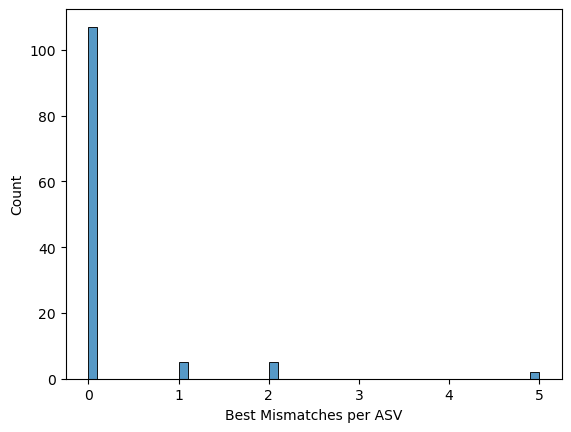

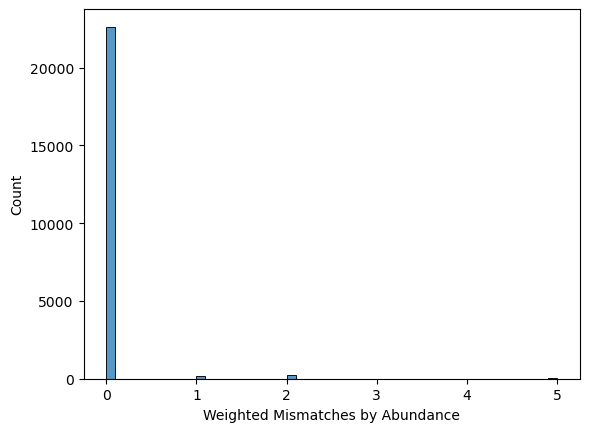


### ITS1 ## mockrobiota-ITS ###

Guessed taxonomy for 990 of 990 reads (100.0%)

### ITS2 ## mockrobiota-ITS ###

d__Fungi; p__Ascomycota; c__Eurotiomycetes; o__Eurotiales; f__Aspergillaceae; g__Penicillium; s__Penicillium_flavigenum and
d__Fungi; p__Ascomycota; c__Eurotiomycetes; o__Eurotiales; f__Aspergillaceae; g__Aspergillus; s__Aspergillus_fumigatus
with 0 mismatches
Guessed taxonomy for 2596 of 2596 reads (100.0%)


In [11]:
## Match expected taxonomies to trueish taxonomies by mapping sequences using tax-credit gapless alignment [excluding full-length amplicon region]
# if rep_seqs matches to multiple taxonomies (due ot limitation of short amplicons) then taxonomy will be selected by lca_mode
# max 5 mismatches are allowed to transfer taxonomy to rep_seqs
# get sequences and taxa files
ref_env = {}
for v_region in v_regions:
    # skip full-length regions
    if v_region in full_length_regions:
        continue

    ref_env[v_region] = {}
    for mock_name in mock_names:
        # skip if region to mock mismatch
        if v_region not in mock_v_regions[mock_name]:
            continue

        # Load original database
        or_ref_db = src.utils.load_db_from_files(
            taxa_path = db_unqza[v_region][mock_name]['taxa'], 
            seqs_path = db_unqza[v_region][mock_name]['seq'])
        # Filter
        mock_taxa = pd.read_csv(
            env_abun_dfs[v_region][mock_name], 
            sep="\t", index_col=None
        )
        mock_taxa = list(mock_taxa['Taxon'])
        or_ref_db_filt = {
            key:items for key, items in or_ref_db.items(
            ) if items['taxa'][6] in ' '.join(mock_taxa)
        }
        # get final sequences and taxa
        fasta_out = join(db_out_files[v_region][mock_name], 'env_seqs.fasta')
        taxa_out = join(db_out_files[v_region][mock_name], 'env_taxa.txt')
        src.utils.download_db_from_dict(
            or_ref_db_filt, 
            taxa_out_file = taxa_out, 
            seqs_out_file = fasta_out)
        ref_env[v_region][mock_name] = [(mock_name, fasta_out, taxa_out)]


# generate trueish taxonomy information
for v_region in v_regions:
    # skip full-length regions
    if v_region in full_length_regions:
        continue
    
    for mock_name in mock_names:
        # skip if region to mock mismatch
        if v_region not in mock_v_regions[mock_name]:
            continue
        
        print(f"\n### {v_region} ## {mock_name} ###\n")
        # Parameters
        if paired[v_region]:
            read_type = 'paired'
        else:
            read_type = 'single'
        # Observed sequences
        observed_sequences = join(
            db_out_files[v_region][mock_name], "source", read_type, 
            f"rep_seqs_{mock_name}.fasta"
        )
        # feature table
        feature_table = join(
                dirname(observed_sequences), f"table_{mock_name}.qza")
        # output trueish taxonomy
        trueish_taxonomy = join(
            db_out_files[v_region][mock_name], "trueish-taxonomies.tsv")
        # generate trueish taxonomy
        src.process_mock.generate_trueish_taxonomies(
            data_dir = db_out_files[v_region][mock_name], 
            feature_table = feature_table,
            expected_sequences = ref_env[v_region][mock_name][0][1],
            expected_taxonomy = ref_env[v_region][mock_name][0][2], 
            observed_sequences = observed_sequences,
            trueish_taxonomy = trueish_taxonomy,
            lca_mode = True,
            reverse_complement = True,
            max_mismatches = 5, 
            force = False
        )


In [12]:
## Full length amplicom only; but can be extended to other amplicon regions as well
# For each mock community and v_region, simulate amplicon by introducing SNPs 
# SNPs are introduced randomly between the range from 0.002 (N=3 SNP across 1500bp) to 0.02 (N=30 SNP across 1500bp)
# reads simulated in replicates id requested
# sha1 hash_id is calculated based on unique sequence identifiers for anonymity
sample_seqs_dict, sample_abu_dict = {}, {}
for v_region in v_regions:
    # skip non full-length regions
    if v_region not in full_length_regions:
        continue

    sample_seqs_dict[v_region] = {}
    sample_abu_dict[v_region] = {}
    for mock_name in mock_names:
        # skip if region to mock mismatch
        if v_region not in mock_v_regions[mock_name]:
            continue

        # Get sequences and taxa
        db_dict = src.utils.load_db_from_files(
                    taxa_path = db_unqza[v_region][mock_name]['taxa'], 
                    seqs_path = db_unqza[v_region][mock_name]['seq'])
        id_to_taxa = {
            ID: {
                'Taxa': src.utils.join_taxa_lineages(record['taxa']),
                'Hash': hashlib.sha1(ID.encode()).hexdigest()[:32]
                }
            for ID, record in db_dict.items()
        }

        # initate a pandas df
        sample_abu_dict[v_region][mock_name] = pd.DataFrame.from_dict(
            id_to_taxa, orient='index').reset_index().rename(columns={'index': 'ID'}
        )
        sample_seqs_dict[v_region][mock_name] = {}

        outdir = db_out_files[v_region][mock_name]
        # load env_abundance
        tab = pd.read_csv(
                join(outdir, "env_abundance.tsv"),
                sep = "\t", index_col = None)
        tab = tab.set_index('Taxon')

        for sample in tab.columns:
            # look up dict taxa to identifier and identifiers to taxa
            sample_identifiers = pd.read_csv(
                join(outdir, f"env-identifiers_{sample}.tsv"),
                sep = "\t", index_col = None)
            sample_identifiers = sample_identifiers.rename(columns={"IDs":"ID"})
            
            # chosen ids to simulate
            ids = [item for sublist in sample_identifiers['ID'].str.split(',') 
                for item in sublist]
            
            # for each replicates of the sample
            for rep in range(1, nsamples_rep + 1):
                sample_id = f"{sample}-{rep}"
                sample_seqs_dict[v_region][mock_name][sample_id] = {}
                
                # prepare sequence information
                id_hash_dict = {}
                for id in ids:
                    # random mutation rate
                    mutation_rate = round(random.uniform(min_mutation, max_mutation), 3)
                    # sha1 hash of id
                    hash_id = hashlib.sha1(id.encode()).hexdigest()[:32]
                    id_hash_dict[id] = hash_id
                    # get mutated dict
                    mutated_dict = src.process_mock.mutate_sequence(
                        seq_dict = db_dict[id], mutation_rate = mutation_rate)
                    sample_seqs_dict[v_region][mock_name][sample_id][hash_id] = mutated_dict
                
                # hash to dict to pandas
                id_hash_dict = pd.DataFrame(id_hash_dict.items(), columns=['ID', 'Hash'])

                # prepare abundance information
                abu = sample_identifiers.copy()
                abu['ID'] = abu['ID'].str.split(',')
                abu = abu.explode('ID').reset_index(drop=True)
                abu["Abundance"] = abu["Abundance"] * nreads_per_feature
                abu = abu.rename(columns={"Abundance": sample_id})
                abu = pd.merge(abu, id_hash_dict, on=['ID'], how='inner')
                abu = abu[['ID', 'Hash', 'Taxa'] + [col for col in abu.columns if col not in ['ID', 'Hash', 'Taxa']]]
                sample_abu_dict[v_region][mock_name] = pd.merge(
                    sample_abu_dict[v_region][mock_name], abu, on=['ID', 'Hash', 'Taxa'], how='outer').fillna(0)



In [13]:
## Full length amplicom only; but can be extended to other amplicon regions as well
# For each mock community and v_region, generate necessary output files for classification and evaluation 
# feature table, rep_seqs fasta file and truish taxonomies for each mutated anonymous sequences generated
for v_region in v_regions:
    # skip non full-length regions
    if v_region not in full_length_regions:
        continue

    for mock_name in mock_names:
        # skip if region to mock mismatch
        if v_region not in mock_v_regions[mock_name]:
            continue

        # define out_files
        outdir = db_out_files[v_region][mock_name]
        src.utils.check_dir(join(outdir, f'source/single'))
        feat_table_biom = join(outdir, f'source/single', f'table_{mock_name}.biom')
        feat_table_tsv = join(outdir, f'source/single', f'table_{mock_name}.tsv')
        expected_taxa_tsv = join(outdir, 'trueish-taxonomies.tsv')
        rep_seq_fasta = join(outdir, f'source/single', f'rep_seqs_{mock_name}.fasta')
        rep_seq_qza = join(outdir, f'source/single', f'rep_seqs_{mock_name}.qza')

        # generate feature table
        if not exists(feat_table_biom) and not exists(feat_table_tsv):
            feat_table = sample_abu_dict[v_region][mock_name]
            feat_table = feat_table.drop(columns=['ID', 'Taxa']).set_index('Hash')
            feat_table = Table(feat_table.values,
                               observation_ids=feat_table.index.tolist(), 
                               sample_ids=feat_table.columns.tolist())
            
            # Save biom table
            with open(feat_table_biom, 'w') as f:
                feat_table.to_json("# Constructed from biom file", f)

            # Save tsv table
            with open(feat_table_tsv, 'w') as f:
                feat_table.to_tsv(direct_io=f)

        # generate trueish taxonomy
        if not exists(expected_taxa_tsv):
            expected_taxa = sample_abu_dict[v_region][mock_name]
            expected_taxa = expected_taxa[['Hash', 'Taxa']].rename(columns={'Hash':'id', 'Taxa':'taxonomy'})
            expected_taxa.to_csv(expected_taxa_tsv, sep="\t", index=False)

        # generate rep_seqs fasta
        if not exists(rep_seq_fasta) and not exists(rep_seq_qza):
            mock_dict = sample_seqs_dict[v_region][mock_name]

            # build a dict for keys (mock identifiers) to sample_ids in which they are randomly simulated
            ids_to_samples = {}
            for sample_id, inner_dict in mock_dict.items():
                for key in inner_dict.keys():
                    ids_to_samples.setdefault(key, []).append(sample_id)

            # next for each identifiers randomly select one sample from which mutated sequence will be used
            randomized_keys = {}
            for key, sample_list in ids_to_samples.items():
                chosen_sample = random.choice(sample_list)
                seq = mock_dict[chosen_sample][key]
                randomized_keys[key] = seq
            
            # save final fasta file
            src.utils.download_db_from_dict(randomized_keys, seqs_out_file = rep_seq_fasta)

            # save final qza file
            cmd = ["qiime", "tools", "import", 
                   "--input-path", rep_seq_fasta, 
                   "--output-path", rep_seq_qza,
                   "--type", "FeatureData[Sequence]"]
            subprocess.run(cmd, check=True)



Imported /home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V1-V9/source/single/rep_seqs_gutmock.fasta as DNASequencesDirectoryFormat to /home/kardokhk/taxonova_bench/benchmark/data/mock-community/gutmock/V1-V9/source/single/rep_seqs_gutmock.qza
Imported /home/kardokhk/taxonova_bench/benchmark/data/mock-community/vaginalmock/V1-V9/source/single/rep_seqs_vaginalmock.fasta as DNASequencesDirectoryFormat to /home/kardokhk/taxonova_bench/benchmark/data/mock-community/vaginalmock/V1-V9/source/single/rep_seqs_vaginalmock.qza
Imported /home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-16S/V1-V9/source/single/rep_seqs_mockrobiota-16S.fasta as DNASequencesDirectoryFormat to /home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-16S/V1-V9/source/single/rep_seqs_mockrobiota-16S.qza
Imported /home/kardokhk/taxonova_bench/benchmark/data/mock-community/mockrobiota-ITS/ITS12/source/single/rep_seqs_mockrobiota-ITS.fasta as DNASequencesDirectoryFor